![Customer Churn Prediction](title_pic.png)

## Machine Learning Workflow

![ML Workflow](ML_roadmap.png)

### 🛒 **Backstory**

An e-commerce company receives thousands of customer reviews about its products every day. Customers share their experiences and opinions regarding product quality, pricing, packaging, delivery, and overall satisfaction.

These reviews contain valuable information that can help the company understand customer preferences and improve its products and services. However, manually analysing a large number of reviews is time-consuming and difficult.

The company wants to use Natural Language Processing (NLP) and Machine Learning techniques to automatically analyse customer reviews and identify whether customers have positive or negative opinions about the products.

---

### 💼 **Business Problem**

The company currently lacks an automated system to analyse and classify customer reviews. This leads to:

- Difficulty in identifying customer satisfaction levels from large volumes of reviews.
- Time-consuming manual analysis of customer feedback.
- Missed opportunities to identify product quality issues.
- Difficulty in understanding customer opinions and expectations.
- Challenges in making data-driven product improvement decisions.

These issues affect customer satisfaction, product quality, and the company's ability to improve its overall business performance.

---

### 🎯 **Business Objective**

To develop an NLP-based Machine Learning classification model that automatically predicts the sentiment of customer product reviews based on their textual content.

The goal is to:

- Analyse customer reviews automatically.
- Classify reviews into positive and negative sentiments.
- Understand customer opinions about products.
- Reduce the time required for manual review analysis.
- Help businesses identify customer satisfaction and product-related issues.
- Support better business decisions using customer feedback.

This model will serve as a decision-support tool to help businesses understand customer opinions and improve product quality and customer satisfaction.
---
### ⚠️ **Constraints**

1. **Data Availability:** The dataset may contain limited customer reviews or incomplete textual information.

2. **Text Complexity:** Customer reviews may contain spelling mistakes, abbreviations, slang, and grammatical errors, making text processing difficult.

3. **Context and Sarcasm:** The model may struggle to understand sarcasm, humour, and context-dependent expressions in customer reviews.

4. **Prediction Errors:** The model may incorrectly classify positive reviews as negative or negative reviews as positive.

5. **Model Performance:** The accuracy of the model depends on the quality, quantity, and diversity of the training data.

6. **Deployment Limitations:** The final solution should allow users to enter a product review and receive a sentiment prediction through a simple interface.

# 1. Data Loading

In [1]:
import pandas as pd

df = pd.read_csv("product_dataset.csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


# 2. Dataset Exploration

## 2.1 Preview of the Dataset

In [2]:
df.head()

,product_name,product_price,Rate,Review,Summary,Sentiment
0,Candes 12 L Room/Personal Air Cooler??????(Whi...,3999,5,super!,great cooler excellent air flow and for this p...,positive
1,Candes 12 L Room/Personal Air Cooler??????(Whi...,3999,5,awesome,best budget 2 fit cooler nice cooling,positive
2,Candes 12 L Room/Personal Air Cooler??????(Whi...,3999,3,fair,the quality is good but the power of air is de...,positive
3,Candes 12 L Room/Personal Air Cooler??????(Whi...,3999,1,useless product,very bad product its a only a fan,negative
4,Candes 12 L Room/Personal Air Cooler??????(Whi...,3999,3,fair,ok ok product,neutral


## 2.2 Dataset Dimensions

In [3]:
df.shape

(205052, 6)

## 2.3 Dataset Information

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 205052 entries, 0 to 205051
Data columns (total 6 columns):
 #   Column         Non-Null Count   Dtype 
---  ------         --------------   ----- 
 0   product_name   205052 non-null  object
 1   product_price  205052 non-null  object
 2   Rate           205052 non-null  object
 3   Review         180388 non-null  object
 4   Summary        205041 non-null  object
 5   Sentiment      205052 non-null  object
dtypes: object(6)
memory usage: 9.4+ MB


## 2.4 Missing Value Analysis

In [5]:
df.isnull().sum()

product_name         0
product_price        0
Rate                 0
Review           24664
Summary             11
Sentiment            0
dtype: int64

## 2.5 Sentiment Distribution

In [6]:
df["Sentiment"].value_counts()

Sentiment
positive    166581
negative     28232
neutral      10239
Name: count, dtype: int64

## 2.6 Sentiment Distribution Visualization

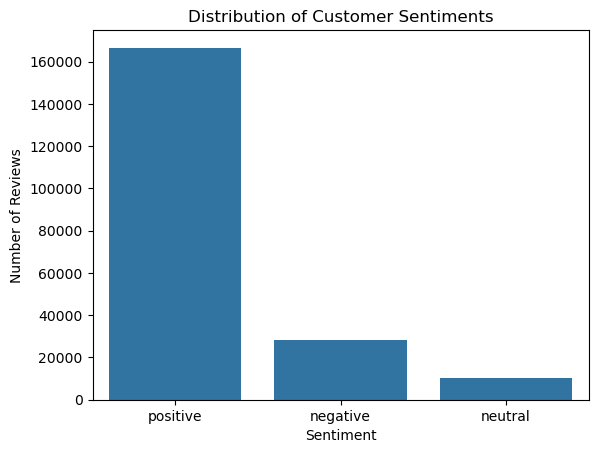

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(data=df, x="Sentiment")
plt.title("Distribution of Customer Sentiments")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.show()

# 3. Data Cleaning

## 3.1 Removing Missing Review Values

In [8]:
df = df.dropna(subset=["Review"])

## 3.2 Checking the Dataset After Removing Missing Values

In [9]:
df.shape

(180388, 6)

## 3.3 Checking Duplicate Records

In [10]:
df.duplicated().sum()

np.int64(25913)

## 3.4 Removing Duplicate Records

In [11]:
df = df.drop_duplicates()

## 3.5 Checking the Cleaned Dataset

In [12]:
df.shape

(154475, 6)

## 3.6 Verifying Duplicate Removal

In [13]:
df.duplicated().sum()

np.int64(0)

## 3.7 Selecting Relevant Columns

In [14]:
df = df[["Review", "Sentiment"]]

## 3.8 Final Dataset Structure

In [15]:
df.head()

,Review,Sentiment
0,super!,positive
1,awesome,positive
2,fair,positive
3,useless product,negative
4,fair,neutral


## 3.9 Sentiment Distribution After Data Cleaning

In [16]:
df["Sentiment"].value_counts()

Sentiment
positive    122813
negative     23353
neutral       8309
Name: count, dtype: int64

# 4. Text Preprocessing

## 4.1 Converting Text to Lowercase

In [17]:
df["Review"]=df["Review"].str.lower()

## 4.2 Removing Special Characters and Numbers

In [18]:
import re

df["Review"] = df["Review"].apply(lambda x: re.sub(r"[^a-zA-Z\s]", "", x))

## 4.3 Removing Extra Spaces

In [19]:
df["Review"] = df["Review"].str.strip()

## 4.4 Removing Stopwords

In [20]:
import nltk
from nltk.corpus import stopwords
nltk.download("stopwords")

stop_words = set(stopwords.words("english"))
stop_words = stop_words - {"not", "no", "nor"}

def remove_stopwords(text):
    words = text.split()
    return " ".join(word for word in words if word not in stop_words)

df["Review"] = df["Review"].apply(remove_stopwords)

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Shant\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


## 4.5 Viewing Preprocessed Reviews

In [21]:
df["Review"].head()

0              super
1            awesome
2               fair
3    useless product
4               fair
Name: Review, dtype: object

## 4.6 Checking Empty Reviews

In [22]:
(df["Review"].str.strip() == "").sum()

np.int64(5)

## 4.7 Removing Empty Reviews

In [23]:
df = df[df["Review"].str.strip() != ""]

## 4.8 Final Cleaned Dataset

In [24]:
df.shape

(154470, 2)

# 5. Preparing Data for Machine Learning

## 5.1 Separating Input and Target Variables

In [25]:
X=df["Review"]
y=df["Sentiment"]

In [26]:
print("input shape:",X.shape)
print("output shape:",y.shape)

input shape: (154470,)
output shape: (154470,)


## 5.3 Text Vectorization Using TF-IDF

In [27]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(max_features=5000)

X_tfidf = tfidf.fit_transform(X)

## 5.4 Checking TF-IDF Features

In [28]:
X_tfidf.shape

(154470, 1188)

## 5.5 Train-Test Split

In [29]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(
    X_tfidf,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [30]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (123576, 1188)
X_test: (30894, 1188)
y_train: (123576,)
y_test: (30894,)


# 6. Model Building

## 6.1 Multinomial Naive Bayes

In [31]:
from sklearn.naive_bayes import MultinomialNB

nb_model = MultinomialNB()

nb_model.fit(X_train, y_train)

,alpha,1.0
,force_alpha,True
,fit_prior,True
,class_prior,None


## 6.2 Model Prediction

In [32]:
y_pred = nb_model.predict(X_test)

## 6.3 Model Accuracy

In [33]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", accuracy * 100, "%")

Model Accuracy: 89.18883925681362 %


In [34]:
from sklearn.linear_model import LogisticRegression

lr_model = LogisticRegression(class_weight="balanced", max_iter=1000)

lr_model.fit(X_train, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,'balanced'
,random_state,None
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


In [35]:
y_pred_lr = lr_model.predict(X_test)

In [36]:
from sklearn.metrics import accuracy_score

lr_accuracy = accuracy_score(y_test, y_pred_lr)

print("Logistic Regression Accuracy:", lr_accuracy * 100, "%")

Logistic Regression Accuracy: 81.48831488314883 %


In [37]:
from sklearn.svm import LinearSVC

svm_model = LinearSVC(class_weight="balanced", max_iter=2000)

svm_model.fit(X_train, y_train)

,penalty,'l2'
,loss,'squared_hinge'
,dual,'auto'
,tol,0.0001
,C,1.0
,multi_class,'ovr'
,fit_intercept,True
,intercept_scaling,1
,class_weight,'balanced'
,verbose,0
,random_state,None


In [38]:
y_pred_svm = svm_model.predict(X_test)

In [39]:
from sklearn.metrics import accuracy_score

svm_accuracy = accuracy_score(y_test, y_pred_svm)

print("SVM Accuracy:", svm_accuracy * 100, "%")

SVM Accuracy: 87.84229947562633 %


In [40]:
results = pd.DataFrame({
    "Model": ["Naive Bayes", "Logistic Regression", "Linear SVM"],
    "Accuracy": [
        accuracy * 100,
        lr_accuracy * 100,
        svm_accuracy * 100
    ]
})

results = results.sort_values(by="Accuracy", ascending=False)

print(results)

                 Model   Accuracy
0          Naive Bayes  89.188839
2           Linear SVM  87.842299
1  Logistic Regression  81.488315


# 7. Testing the Model with New Reviews

In [41]:
new_reviews = [
    "This product is excellent and amazing",
    "Very bad product, completely disappointed",
    "The product is average"
]

new_reviews_tfidf = tfidf.transform(new_reviews)

predictions = nb_model.predict(new_reviews_tfidf)

for review, sentiment in zip(new_reviews, predictions):
    print("Review:", review)
    print("Predicted Sentiment:", sentiment)
    print()

Review: This product is excellent and amazing
Predicted Sentiment: positive

Review: Very bad product, completely disappointed
Predicted Sentiment: negative

Review: The product is average
Predicted Sentiment: positive



## Checking Saved Model Files (Before Deployment)

In [42]:
import joblib

joblib.dump(nb_model, "sentiment_model.pkl")
joblib.dump(tfidf, "tfidf_vectorizer.pkl")

print("Model and vectorizer saved successfully!")

Model and vectorizer saved successfully!


In [43]:
import os

print(os.listdir())

['.gradio', '.ipynb_checkpoints', 'anaconda_projects', 'app.py', 'ML_roadmap.png', 'product_dataset.csv', 'product_review.ipynb', 'sentiment_model.pkl', 'tfidf_vectorizer.pkl', 'title_pic.png']


In [44]:
import gradio as gr
import joblib

model = joblib.load("sentiment_model.pkl")
tfidf = joblib.load("tfidf_vectorizer.pkl")

def predict_sentiment(review):
    review = tfidf.transform([review])
    prediction = model.predict(review)
    return prediction[0].capitalize()

demo = gr.Interface(
    fn=predict_sentiment,
    inputs=gr.Textbox(label="Enter Product Review"),
    outputs=gr.Textbox(label="Predicted Sentiment"),
    title="Product Review Sentiment Analysis"
)

demo.launch(share=True)


* Running on local URL:  http://127.0.0.1:7860
* Running on public URL: https://28d914b1dd84d78815.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
1